# Lab 02: Visualization
This lab revisits the lecture *Data Visualization*.

| Task | Topic |
|---|---|
| 0 | matplotlib warm-up (just run and read) |
| 1 | Bar plots: the distribution of a categorical variable |
| 2 | Histograms and bin width |
| 3 | Comparing distributions: box plots and violin plots |
| 4 | Encoding channels (read only) |
| 5 | Straightening a relationship with a log transform |
| 6 | What's wrong with this plot? |

Fill in the cells marked `# YOUR CODE HERE` and run the test cell below each one.
Plan for about 60 minutes.
Datasets: `data/babyweights.csv` (1174 mother–baby pairs, the lecture's baby weights data)
plus two seaborn built-ins (`iris`, `mpg`).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()  # seaborn's default style for all plots below

## Setting
The lecture built most of its plots on the **baby weights** dataset: 1174 mother–baby pairs
from the Child Health and Development Studies (CHDS). Birth weights are measured in ounces.

In [6]:
babies = pd.read_csv("data/babyweights.csv")
print(babies.shape)
babies.head()

(1174, 6)


,Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
0,120,284,27,62,100,False
1,113,282,33,64,135,False
2,128,279,28,64,115,True
3,108,282,23,67,125,True
4,136,286,25,62,93,False


## Task 0: matplotlib warm-up (nothing to solve)
Run the cell below and read it carefully. Every plot in this lab uses this *object-oriented*
pattern: create a `figure` (the canvas), get one or more `axes` (the actual plots), then draw
on them.

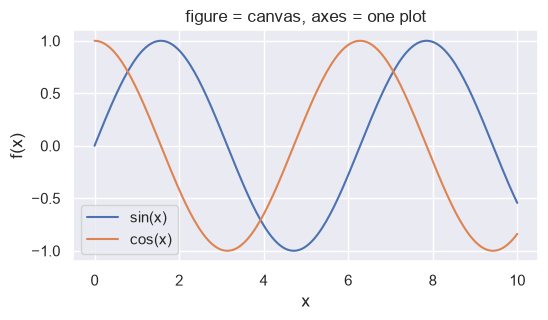

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
x = np.linspace(0, 10, 200)
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), label="cos(x)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("figure = canvas, axes = one plot")
ax.legend()
plt.show()  # only needed in scripts; Jupyter shows the figure anyway

## Task 1: Bar plots
A **bar plot** shows the distribution of a *categorical* variable: one bar per category,
bar height = count (or share).

The `Maternal Smoker` column contains `True`/`False`.

1. Compute how often each value occurs and store the result in `smoker_counts`.
   *Hint:* `.value_counts()` on the column does the counting for you.
2. Draw a bar plot of the counts and label the axes. Remember: the bar length must encode
   the count — never start a bar axis above 0.

1174


Text(0.5, 1.0, 'Maternal Smokers')

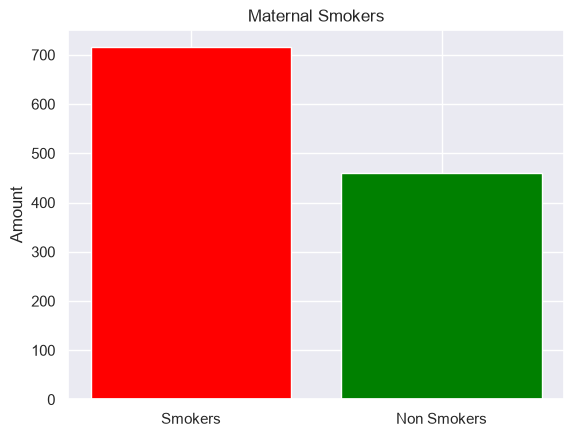

In [33]:
# YOUR CODE HERE

smoker_counts = babies["Maternal Smoker"].value_counts()
print(smoker_counts.sum())

fig, ax = plt.subplots()

barlabels = ["Smokers", "Non Smokers"]

ax.bar(barlabels, smoker_counts, color=["red", "green"])
ax.set_ylabel("Amount")
ax.set_title("Maternal Smokers")

In [34]:
assert len(babies) == 1174, "Did the CSV load correctly?"
assert smoker_counts.sum() == 1174
assert set(smoker_counts.index) == {True, False}

**Question:** Why is a bar plot the right tool here — and a histogram the wrong one?


YOUR ANSWER HERE

## Task 2: Histograms and bin width
A **histogram** shows the distribution of a *quantitative* variable. Remember: in a histogram,
**area = proportion**.

1. Draw a histogram of `Birth Weight` with `bins=25` and label the axes.
2. Compute the share of babies with a birth weight in $[100, 120)$ ounces and store it in
   `share_100_120`.
   *Hint:* a boolean mask `(...) & (...)`, then `.mean()` gives a share.

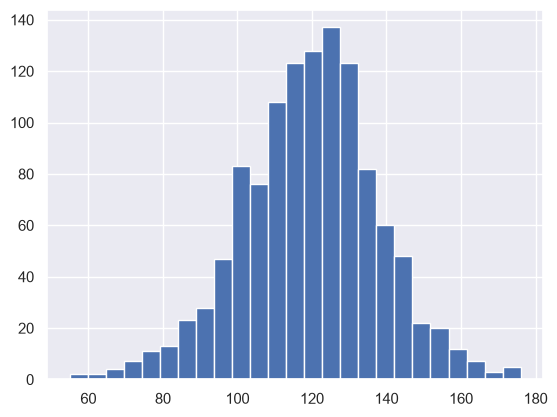

In [47]:
# YOUR CODE HERE

fig, ax = plt.subplots()

ax.hist(babies["Birth Weight"], bins=25)

mask = (babies["Birth Weight"] >= 100) & (babies["Birth Weight"] < 120)

share_100_120 = mask.mean()

In [48]:
assert 0 < share_100_120 < 1, "A share must be between 0 and 1"
assert np.isclose(share_100_120, 0.36030664395229983)

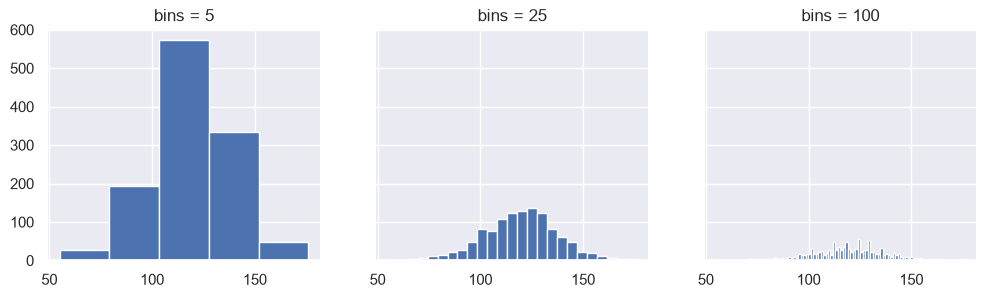

In [49]:
# Same data, three bin widths:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, bins in zip(axes, [5, 25, 100]):
    ax.hist(babies["Birth Weight"], bins=bins)
    ax.set_title(f"bins = {bins}")
plt.show()
# Same data, three bin widths — what does the bin width change,
# and what is the trade-off? (No code here, just look.)


## Task 3: Comparing distributions: box plots and violin plots
Does maternal smoking go along with lower birth weight?

1. Draw **side-by-side box plots** of `Birth Weight`, one per value of `Maternal Smoker`,
   with `sns.boxplot(data=babies, x="Maternal Smoker", y="Birth Weight")`.
2. Compute the mean birth weight per group and store it in `group_means`.
   *Hint:* `groupby`.

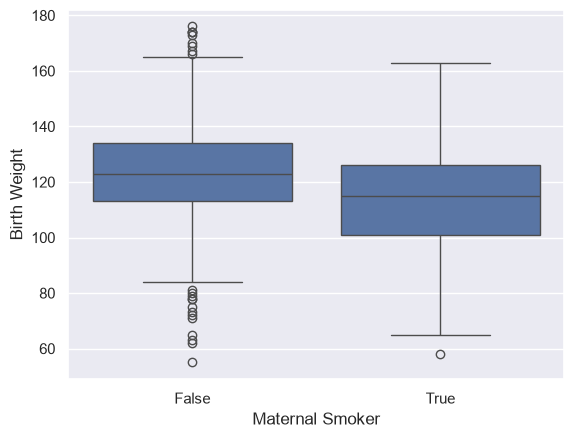

In [63]:
# YOUR CODE HERE

sns.boxplot(data=babies, x="Maternal Smoker", y="Birth Weight")

group_means = babies.groupby("Maternal Smoker")["Birth Weight"].mean()

In [64]:
assert set(group_means.index) == {True, False}
assert np.isclose(group_means[False], 123.08531468531469)
assert np.isclose(group_means[True], 113.81917211328977)

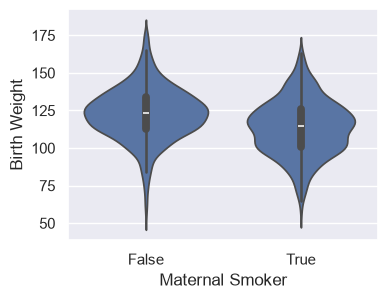

In [66]:
# The same comparison as violin plots:
fig, ax = plt.subplots(figsize=(4, 3))
sns.violinplot(data=babies, x="Maternal Smoker", y="Birth Weight", ax=ax)
plt.show()

**Question:** Which group is lighter, by how much — and what does the violin show that the
box plot hides?


YOUR ANSWER HERE

## Task 4: Encoding channels (read only)

An **encoding** maps a variable to a visual element (position, length, color, area, …).
Channels are not equally precise: position beats color and area.

The `iris` dataset (a seaborn built-in) has four measurements for 150 flowers of three
species. The next cells load it and draw the same scatter plot with three variables encoded.


In [67]:
iris = sns.load_dataset("iris")
print(iris.shape)
iris.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


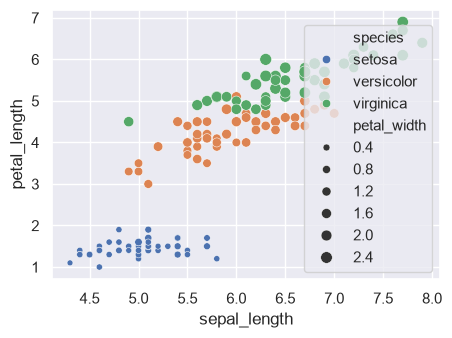

In [68]:
# The same scatter plot, but with petal width additionally encoded as size:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.scatterplot(data=iris, x="sepal_length", y="petal_length",
                hue="species", size="petal_width", ax=ax)
plt.show()

**Question:** How many variables are encoded above, and which channel reads off values most
precisely?


Position as in petal lenght and sepal length, specieses in colors and petal width in the dot size. The most precise is the color encoding here 

## Task 5: Straightening a relationship with a log transform
The `mpg` dataset (another seaborn built-in) has the fuel economy of 398 cars. Heavier cars
drive fewer miles per gallon — but the relationship looks like a **curve**, not a line.

The next cell draws the raw scatter plot.

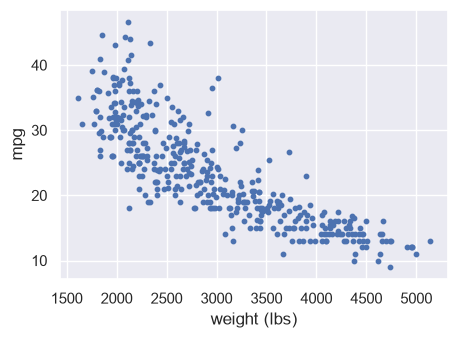

In [69]:
mpg = sns.load_dataset("mpg")
weight = mpg["weight"].to_numpy()
mpg_vals = mpg["mpg"].to_numpy()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(weight, mpg_vals, s=10)
ax.set_xlabel("weight (lbs)")
ax.set_ylabel("mpg")
plt.show()

If $\text{mpg} = C \cdot \text{weight}^{a}$, then $\log_{10}(\text{mpg})$ vs.
$\log_{10}(\text{weight})$ is a straight line with slope $a$ (the lecture's power law).

1. Compute the correlation of the raw data: `r_raw = np.corrcoef(weight, mpg_vals)[0, 1]`.
2. Compute the correlation of the **log-transformed** data with `np.log10`: `r_log`.


In [73]:
# YOUR CODE HERE

r_raw = np.corrcoef(weight, mpg_vals)[0, 1]

r_log = np.corrcoef(np.log10(weight), np.log10(mpg_vals))[0, 1]


In [74]:
assert -1 < r_raw < 0 and -1 < r_log < 0, "Both correlations should be negative"
assert np.isclose(r_raw, -0.8317409332443352)
assert np.isclose(r_log, -0.8744685942470197)
assert abs(r_log) > abs(r_raw), "The log transform should straighten the relationship"


## Task 6: What's wrong with this plot?
The next cell draws a figure that breaks several rules from the lecture (scale, perception,
context). Run it, look at it, then answer below.

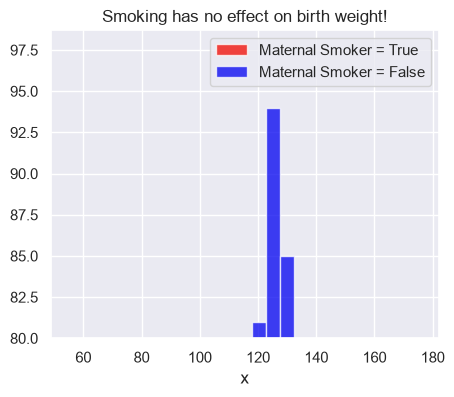

In [75]:
# Two overlaid histograms, a truncated y-axis, and a very confident title:
fig, ax = plt.subplots(figsize=(5, 4))
for smoker in (True, False):
    sub = babies.loc[babies["Maternal Smoker"] == smoker, "Birth Weight"]
    ax.hist(sub, bins=25, alpha=0.75, color=plt.cm.jet(0.9 if smoker else 0.1),
            label=f"Maternal Smoker = {smoker}")
ax.set_ylim(bottom=80)  # "zoom in" on the tall part
ax.set_title("Smoking has no effect on birth weight!")
ax.set_xlabel("x")
ax.legend()
plt.show()

**Question (a):** Name two things that are wrong with this figure — and what each of
them does to the reader.


The axes dont have correct labeling, The title frames the Data instead of the Data showing the effect. Maternal Smoker = True/False is understandebel but could be worded better. The Mothers that smoke seem the be hidden behind the Nonsmokers Bars. 

**(b)** Redraw it honestly (y-axis from 0, default colours, informative labels, neutral
title) and store the medians of `Birth Weight` in the two groups as `median_nonsmoker` and
`median_smoker` — the difference is what the bad figure hid.


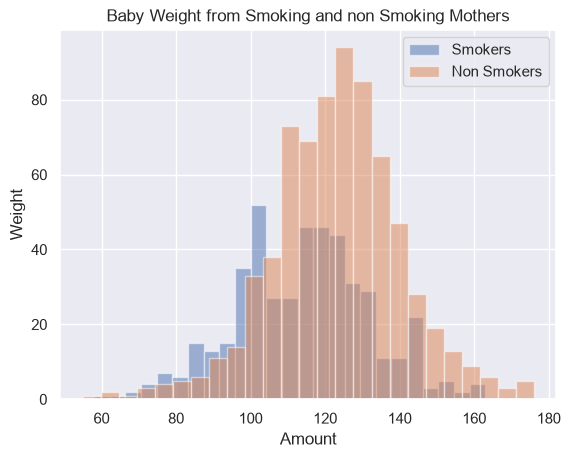

In [94]:
# YOUR CODE HERE
fig, ax = plt.subplots()

labels = ("Smokers", "Non Smokers")

for smoker, l in zip((True, False), labels):
    sub = babies.loc[babies["Maternal Smoker"] == smoker, "Birth Weight"]
    ax.hist(sub, bins=25, alpha=0.5, label=l)

ax.set_title("Baby Weight from Smoking and non Smoking Mothers")
ax.set_ylabel("Weight")
ax.set_xlabel("Amount")
ax.legend()

median_nonsmoker = babies.loc[babies["Maternal Smoker"] == False, "Birth Weight"].median()
median_smoker = babies.loc[babies["Maternal Smoker"] == True, "Birth Weight"].median()

In [95]:
assert median_nonsmoker > median_smoker
assert np.isclose(median_nonsmoker, 123.0)
assert np.isclose(median_smoker, 115.0)

## Wrap-up
- **Plot first, then quantify**: the scatter suggested a curve, the correlation measured the
  strength, the log transform turned it into a line.
- Bar plot → categories; histogram → numbers; box/violin → comparing groups.
- Bin width and axis ranges are choices — make them honestly (area = proportion, y from 0
  for counts).
- Channels are not equally precise: position > length > angle/area > color.

**Next week:** Data Cleaning (leftover questions on this notebook roll into the start of the
session).